In [37]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from keras.models import Sequential
from keras.layers import Dense,Input


In [2]:
df = pd.read_csv('data.csv')
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [3]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
df.drop(['id','Unnamed: 32'],axis=1,inplace=True)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

In [6]:
#Split Features and Labels
X = df.drop('diagnosis',axis=1)
Y = df['diagnosis']

In [7]:
Y_diagnosis = ({'B':0,'M':1})
Y = Y.map(Y_diagnosis)

In [8]:
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [9]:
X_train.shape

(455, 30)

In [10]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [11]:
model=Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32,activation='relu'),
    Dense(16,activation='relu'),
    Dense(1,activation='sigmoid')
])

In [12]:
model.compile(
    optimizer='adam',
    loss ='binary_crossentropy',
    metrics =['accuracy']
)

In [13]:
history = model.fit(X_train,Y_train,epochs=10,batch_size=32,validation_split=0.1)

Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.4108 - loss: 0.8147 - val_accuracy: 0.5217 - val_loss: 0.6888
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7555 - loss: 0.5834 - val_accuracy: 0.8043 - val_loss: 0.5179
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8900 - loss: 0.4520 - val_accuracy: 0.8696 - val_loss: 0.4072
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9169 - loss: 0.3567 - val_accuracy: 0.8696 - val_loss: 0.3283
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9291 - loss: 0.2883 - val_accuracy: 0.9130 - val_loss: 0.2706
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9291 - loss: 0.2363 - val_accuracy: 0.9130 - val_loss: 0.2291
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9413 - loss: 0.1970 - val_accuracy: 0.9130 - val_loss: 0.1985
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9438 - loss: 0.1692 - val_accuracy: 0.9348 - v

In [14]:
model.evaluate(X_test,Y_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9737 - loss: 0.1041


[0.10406405478715897, 0.9736841917037964]

In [15]:
pred_probability = model.predict(X_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


In [16]:
predictions = (pred_probability>0.5).astype(int)

In [17]:
accuracy = accuracy_score(predictions,Y_test)
accuracy

0.9736842105263158

In [18]:
history.history

{'accuracy': [0.41075795888900757,
  0.7555012106895447,
  0.8899755477905273,
  0.9168704152107239,
  0.9290953278541565,
  0.9290953278541565,
  0.9413203001022339,
  0.9437652826309204,
  0.95110023021698,
  0.9633252024650574],
 'loss': [0.814716637134552,
  0.5833581686019897,
  0.4520343244075775,
  0.3567380905151367,
  0.28828948736190796,
  0.23628363013267517,
  0.19699802994728088,
  0.16918528079986572,
  0.14639882743358612,
  0.12930582463741302],
 'val_accuracy': [0.52173912525177,
  0.804347813129425,
  0.8695651888847351,
  0.8695651888847351,
  0.9130434989929199,
  0.9130434989929199,
  0.9130434989929199,
  0.9347826242446899,
  0.95652174949646,
  0.97826087474823],
 'val_loss': [0.6887926459312439,
  0.5178647041320801,
  0.4072345793247223,
  0.3283207416534424,
  0.27059701085090637,
  0.22905944287776947,
  0.1984652429819107,
  0.1744663417339325,
  0.15669387578964233,
  0.1427728235721588]}

In [19]:
cm = confusion_matrix(predictions,Y_test)
cm

array([[70,  2],
       [ 1, 41]])

In [24]:
cm_df = pd.DataFrame(cm,index=['Actual Benign','Actual Malignant'],columns=['Predicted Benign','Predicted Malignant'])

In [25]:
cm_df

,Predicted Benign,Predicted Malignant
Actual Benign,70,2
Actual Malignant,1,41


Text(0.5, 1.0, 'Artificial Neural Network')

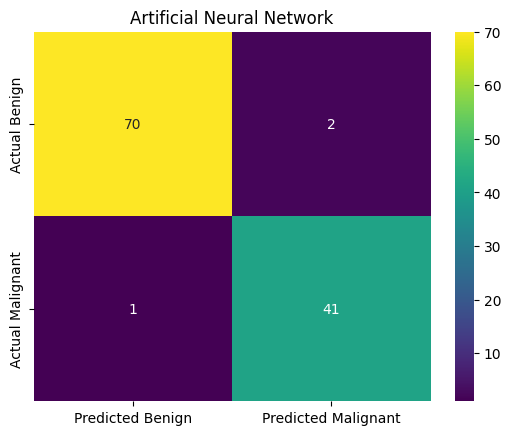

In [38]:
sns.heatmap(cm_df,annot=True,fmt='d',cmap='viridis')
plt.title("Artificial Neural Network")

In [27]:
cf = classification_report(predictions,Y_test,output_dict=True)
cf_df = pd.DataFrame(cf).transpose()
cf_df

,precision,recall,f1-score,support
0,0.985915,0.972222,0.979021,72.000000
1,0.953488,0.976190,0.964706,42.000000
accuracy,0.973684,0.973684,0.973684,0.973684
macro avg,0.969702,0.974206,0.971863,114.000000
weighted avg,0.973969,0.973684,0.973747,114.000000
